In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix

import plotly.express as px


In [7]:

import pandas as pd

df = pd.read_excel("week10_students.xlsx")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (150, 9)


,student_id,name,gender,program,district,attendance_pct,quiz_avg,assignments_avg,score
0,AUCA001,Aline Uwase,F,Information Systems,Gasabo,55,31.0,35.0,28.6
1,AUCA002,Eric Iradukunda,M,Software Engineering,Musanze,73,61.1,76.7,64.5
2,AUCA003,Diane Uwizeyimana,F,Networking,Muhanga,92,35.2,65.5,52.7
3,AUCA004,Jean Bosco Ikirezi,M,Accounting,Kicukiro,69,65.2,54.2,68.3
4,AUCA005,Patrick Ingabire,M,Information Systems,Huye,88,39.3,42.9,42.3


In [36]:

features = ["quiz_avg", "assignments_avg", "attendance_pct"]

for feature in features:
    correlation = df[feature].corr(df["score"])
    print(feature, ":", round(correlation, 4))

    
# quiz_avg looks most useful because it has
# the highest correlation with score (0.8007).



quiz_avg : 0.8007
assignments_avg : 0.536
attendance_pct : 0.2381


In [9]:

X = df[["quiz_avg", "assignments_avg", "attendance_pct"]]

y = df["score"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (150, 3)
y shape: (150,)


In [37]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))


# We use 75% of the data to train the model.
# The remaining 25% is kept for testing.
# This helps us evaluate the model on unseen data.



Training students: 112
Testing students: 38


In [11]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [12]:

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", round(coefficient, 4))

print("Intercept:", round(model.intercept_, 4))


quiz_avg : 0.579
assignments_avg : 0.3648
attendance_pct : 0.1134
Intercept: -4.4282


In [13]:

y_pred = model.predict(X_test)

print("Predicted scores:", y_pred[:5])
print("Actual scores:", y_test.iloc[:5].values)


Predicted scores: [73.80411597 66.20592948 52.17706824 58.23206592 64.4613729 ]
Actual scores: [71.4 69.3 55.6 65.1 61.2]


In [38]:

from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("R2:", round(r2, 2))


# The model predicts students' final scores with
# an average error of approximately 3.3 points.
#
# The R2 score of 0.89 means that the model explains
# about 89% of the differences in students' scores.
#
# This suggests that the model makes reasonably
# accurate predictions on unseen student data.


MAE: 3.33
R2: 0.89


In [15]:

new_student = pd.DataFrame({
    "quiz_avg": [70],
    "assignments_avg": [75],
    "attendance_pct": [90]
})

print(new_student)


   quiz_avg  assignments_avg  attendance_pct
0        70               75              90


In [16]:

predicted_score = model.predict(new_student)

print("Predicted final score:", round(predicted_score[0], 2))


Predicted final score: 73.66


In [39]:

my_data = pd.DataFrame({
    "quiz_avg": [85],
    "assignments_avg": [90],
    "attendance_pct": [95]
})

my_prediction = model.predict(my_data)

print("My predicted score:", round(my_prediction[0], 2))


# The trained regression model predicts the final
# score using quiz average, assignments average,
# and attendance percentage.
#
# These predictions are estimates, not guaranteed
# final scores.



My predicted score: 88.39


In [18]:

df["passed"] = (df["score"] >= 50).astype(int)

print(df["passed"].value_counts())


passed
1    131
0     19
Name: count, dtype: int64


In [19]:

Xc = df[["quiz_avg", "assignments_avg", "attendance_pct"]]

yc = df["passed"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc,
    yc,
    test_size=0.25,
    random_state=42
)

print("Training students:", len(Xc_train))
print("Testing students:", len(Xc_test))


Training students: 112
Testing students: 38


In [40]:

from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(max_iter=1000)

classifier.fit(Xc_train, yc_train)

print("Classification model trained successfully!")



# We created a binary target called "passed".
# Students with scores >= 50 are classified as 1 (Pass).
# Students with scores below 50 are classified as 0 (Fail).
#
# We trained a Logistic Regression model to predict
# whether a student will pass or fail.


Classification model trained successfully!


In [21]:

from sklearn.metrics import accuracy_score

yc_pred = classifier.predict(Xc_test)

accuracy = accuracy_score(yc_test, yc_pred)

print("Model Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")


Model Accuracy: 0.8947
Accuracy Percentage: 89.47 %


In [22]:

baseline = yc_test.mean()

print("Lazy Baseline:", round(baseline, 4))
print("Baseline Percentage:", round(baseline * 100, 2), "%")


Lazy Baseline: 0.8947
Baseline Percentage: 89.47 %


In [41]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(yc_test, yc_pred)

print("Confusion Matrix:")
print(cm)


# The model accuracy is close to the lazy baseline.
# This does not automatically mean the model is useless.
#
# We must examine the confusion matrix to see whether
# the model correctly identifies students who fail.
#
# A useful model should help identify at-risk students,
# not simply predict that everyone will pass.



Confusion Matrix:
[[ 3  1]
 [ 3 31]]


In [24]:

X1 = df[["quiz_avg"]]
y = df["score"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y, test_size=0.25, random_state=42
)

model1 = LinearRegression()
model1.fit(X1_train, y1_train)

pred1 = model1.predict(X1_test)
r2_1 = r2_score(y1_test, pred1)

print("Model 1 R2:", round(r2_1, 2))


Model 1 R2: 0.62


In [25]:

X2 = df[["quiz_avg", "assignments_avg", "attendance_pct"]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)

pred2 = model2.predict(X2_test)
r2_2 = r2_score(y2_test, pred2)

print("Model 2 R2:", round(r2_2, 2))


Model 2 R2: 0.89


In [26]:

X3 = df[[
    "quiz_avg",
    "assignments_avg",
    "attendance_pct",
    "program"
]]

X3 = pd.get_dummies(X3, columns=["program"], dtype=int)

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.25, random_state=42
)

model3 = LinearRegression()
model3.fit(X3_train, y3_train)

pred3 = model3.predict(X3_test)
r2_3 = r2_score(y3_test, pred3)

print("Model 3 R2:", round(r2_3, 2))


Model 3 R2: 0.88


In [42]:

print("Model 1 (Quiz only):", round(r2_1, 2))
print("Model 2 (Three features):", round(r2_2, 2))
print("Model 3 (With program):", round(r2_3, 2))


# Model 1 uses only quiz scores.
# Model 2 adds assignments and attendance.
# Model 3 also includes the student's program.
#
# Adding assignments and attendance improves R2.
# Adding program does not improve the test R2.
#
# This shows that more features do not always
# lead to better predictions.



Model 1 (Quiz only): 0.62
Model 2 (Three features): 0.89
Model 3 (With program): 0.88


In [28]:

import plotly.express as px


In [29]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


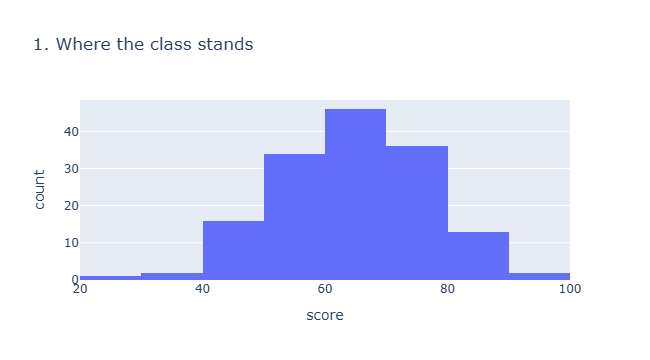

In [30]:

fig1 = px.histogram(
    df,
    x="score",
    nbins=12,
    title="1. Where the class stands"
)

fig1.show()


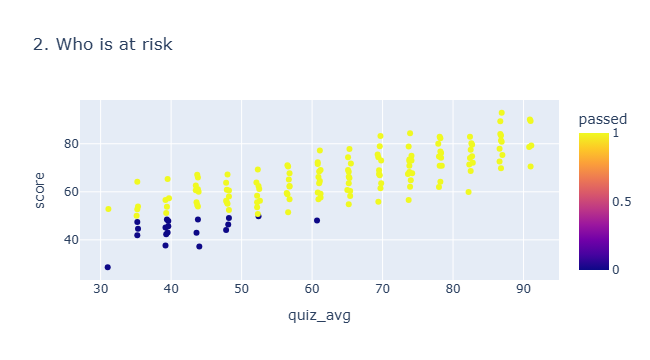

In [31]:

df["passed"] = (df["score"] >= 50).astype(int)

fig2 = px.scatter(
    df,
    x="quiz_avg",
    y="score",
    color="passed",
    hover_name="name",
    title="2. Who is at risk"
)

fig2.show()


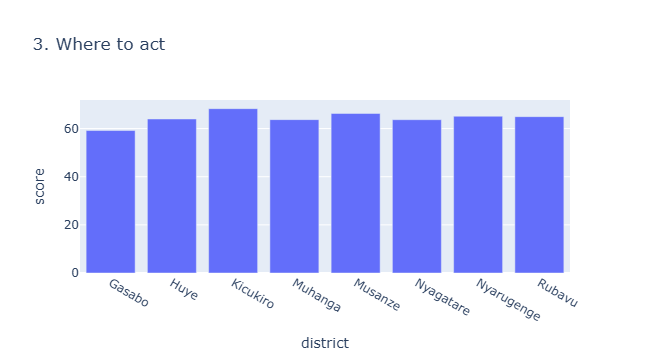

In [32]:

district_avg = df.groupby(
    "district",
    as_index=False
)["score"].mean()

fig3 = px.bar(
    district_avg,
    x="district",
    y="score",
    title="3. Where to act"
)

fig3.show()


In [43]:

fig2.write_html("class_dashboard.html")

print("Dashboard saved successfully!")


# The histogram shows the distribution of final scores.
# The scatter plot identifies students who passed or failed.
# The bar chart compares average scores by district.
#
# The interactive scatter plot was exported as an HTML
# dashboard for viewing in a web browser.



Dashboard saved successfully!


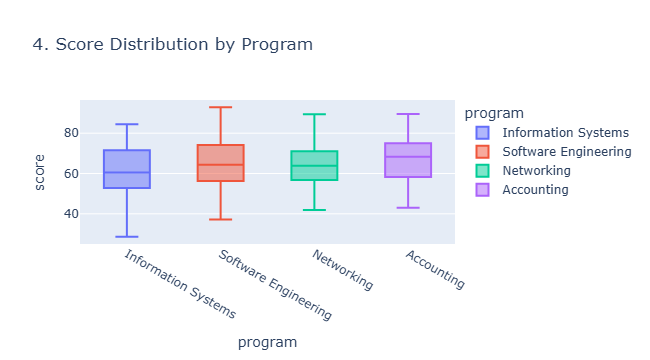

In [34]:

fig4 = px.box(
    df,
    x="program",
    y="score",
    color="program",
    title="4. Score Distribution by Program"
)

fig4.show()


In [45]:

program_spread = df.groupby("program")["score"].agg(
    lambda x: x.quantile(0.75) - x.quantile(0.25)
)

print(program_spread.sort_values())

print("Most consistent:", program_spread.idxmin())
print("Widest spread:", program_spread.idxmax())


program
Networking              13.90
Accounting              16.60
Information Systems     17.65
Software Engineering    17.70
Name: score, dtype: float64
Most consistent: Networking
Widest spread: Software Engineering
